<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="300" alt="Skills Network Logo">
    </a>
</p>


# Test Environment for Generative AI classroom labs

This lab provides a test environment for the codes generated using the Generative AI classroom.

Follow the instructions below to set up this environment for further use.


# Setup


### Install required libraries

In case of a requirement of installing certain python libraries for use in your task, you may do so as shown below.


In [1]:
# Install required libraries
# %pip install nbformat plotly seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import Ridge

### Dataset URL from the GenAI lab
Use the URL provided in the GenAI lab in the cell below. 


In [2]:
# Dataset URL from the GenAI lab
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMSkillsNetwork-AI0271EN-SkillsNetwork/labs/v1/m3/data/used_car_price_analysis.csv"
df = pd.read_csv(URL)

In [3]:
# Inspect the first few rows and shape of the dataframe
df.head()
df.shape

(17966, 9)

### Downloading the dataset

Execute the following code to download the dataset in to the interface.

> Please note that this step is essential in JupyterLite. If you are using a downloaded version of this notebook and running it on JupyterLabs, then you can skip this step and directly use the URL in pandas.read_csv() function to read the dataset as a dataframe


In [4]:
# from pyodide.http import pyfetch

# async def download(url, filename):
#     response = await pyfetch(url)
#     if response.status == 200:
#         with open(filename, "wb") as f:
#             f.write(await response.bytes())

# path = URL

# await download(path, "dataset.csv")
# file_name  = "dataset.csv"

---


# Test Environment


In [5]:
# Identify columns containing missing values
missing_columns = df.columns[df.isna().any()].tolist()

# Replace missing values with each column's mean
df.fillna(df.mean(numeric_only=True), inplace=True)

# Delete duplicate rows
df.drop_duplicates(inplace=True)

# Print the list of columns with missing values
print(missing_columns)

# Save the cleaned DataFrame to a CSV file
df.to_csv('cleaned_dataset.csv', index=False)

['tax']


In [6]:
# Re-import the processed dataset after augmentation with "howtocsv.com"
df = pd.read_csv('cleaned_dataset_processed.csv')

In [7]:
# Re-inspect the first few rows and shape of the dataframe
df.head()
df.shape

(26718, 10)

In [8]:
# Calculate correlations with the target variable
correlations = df.corr(numeric_only=True)["price"].drop("price")

# Select the 5 features with the strongest correlations
top_features = correlations.abs().nlargest(5).index.tolist()

# Print the most correlated features
print(top_features)

['year', 'mileage', 'engineSize', 'tax', 'mpg']


In [9]:
# Count cars for each fuel type
fuel_type_counts = df["fuelType"].value_counts()

# Print the counts of each fuel type
print(fuel_type_counts)

fuelType
Petrol      18090
Diesel       8595
Hybrid         29
Electric        3
Other           1
Name: count, dtype: int64


C:\Users\kyleh\AppData\Local\Temp\ipykernel_15288\2113164715.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="transmission", y="price", order=order, palette="viridis")


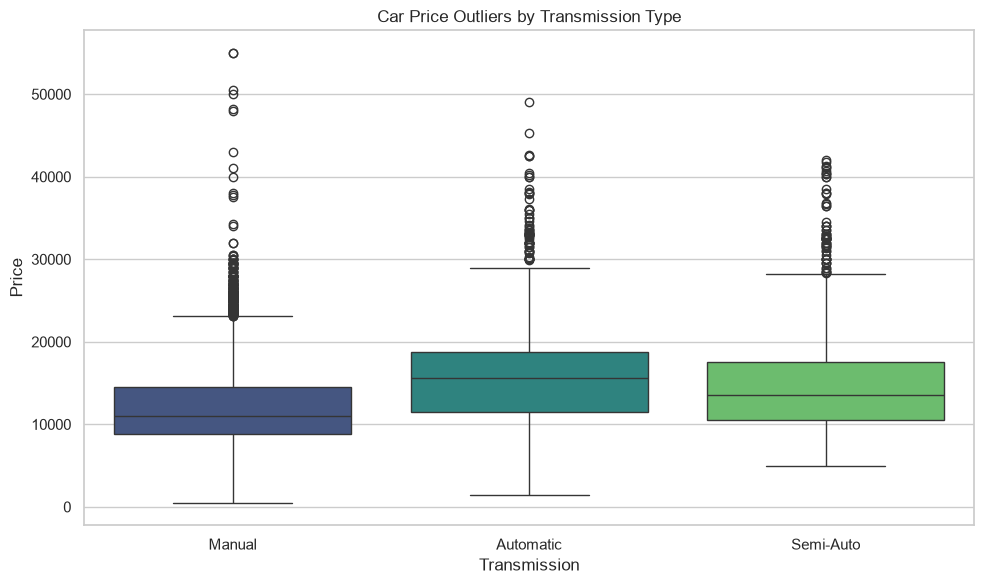

In [10]:
# Ensure a clean style
sns.set_theme(style="whitegrid")

# Optional: define order of transmission categories based on median price to make the plot clearer
order = df["transmission"].value_counts().index

# Create a box plot of price grouped by transmission type
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="transmission", y="price", order=order, palette="viridis")

# Add plot labels and display the chart
plt.title("Car Price Outliers by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

## Authors


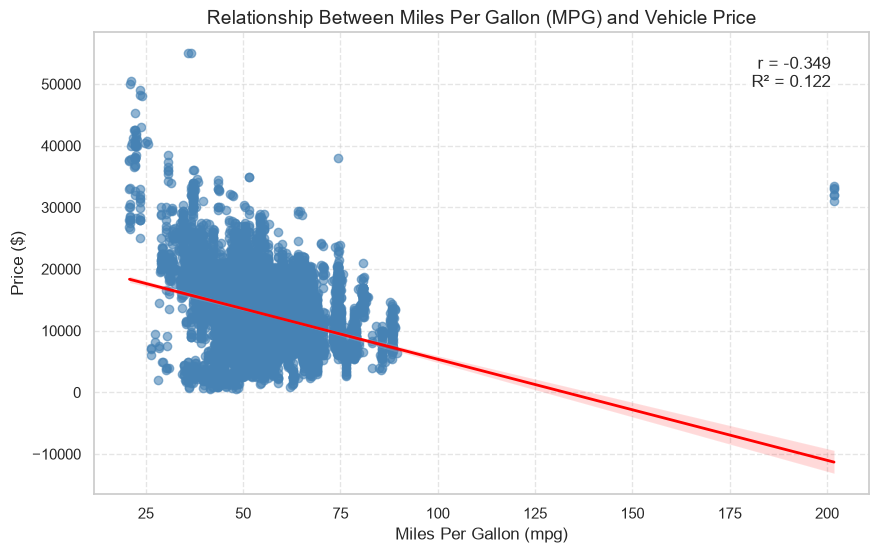

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the visual style of the plot
sns.set_theme(style="whitegrid")

# Create a figure with a specific size for better readability
plt.figure(figsize=(10, 6))

# Generate a regression plot between mpg and price
# Use a slightly higher alpha for better visibility and a neutral color for points
sns.regplot(
    data=df,
    x="mpg",
    y="price",
    scatter_kws={"alpha": 0.6, "color": "steelblue"},
    line_kws={"color": "red", "linewidth": 2},
)

# Compute correlation coefficient and R-squared for annotation
r = df["mpg"].corr(df["price"])
r_squared = r ** 2
# Add plot labels
plt.title("Relationship Between Miles Per Gallon (MPG) and Vehicle Price", fontsize=14)
plt.xlabel("Miles Per Gallon (mpg)", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)

# Add a text box with the correlation statistics
plt.text(
    0.95,
    0.95,
    f"r = {r:.3f}\nR² = {r_squared:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
)

# Optionally, add a grid for improved readability
plt.grid(True, linestyle="--", alpha=0.5)

# Display the plot
plt.show()

In [ ]:
# Linear Regression Model: Predicting Car Price from MPG
# Keep rows with valid mpg and price values
model_data = df[["mpg", "price"]].dropna()

# Prepare feature and target variables
X = model_data[["mpg"]]
y = model_data["price"]

# Fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Generate predictions
predictions = model.predict(X)

# Calculate evaluation metrics
r_squared = r2_score(y, predictions)
mean_squared_error_value = mean_squared_error(y, predictions)

# Print the evaluation metrics
print("R-Squared:", r_squared)
print("Mean Squared Error:", mean_squared_error_value)

R-Squared: 0.1215407275021606
Mean Squared Error: 19826079.46609024


In [ ]:
# Linear Regression Model for Vehicle Price Prediction
# Select the required features and target
model_data = df[
    ["year", "mileage", "tax", "mpg", "engineSize", "price"]
].dropna()

X = model_data[["year", "mileage", "tax", "mpg", "engineSize"]]
y = model_data["price"]

# Fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Generate predictions
predictions = model.predict(X)

# Calculate evaluation metrics
r_squared = r2_score(y, predictions)
mean_squared_error_value = mean_squared_error(y, predictions)

# Print the evaluation metrics
print("R-Squared:", r_squared)
print("Mean Squared Error:", mean_squared_error_value)

R-Squared: 0.7321084399546459
Mean Squared Error: 6046084.917120775


In [ ]:
# Polynomial Regression for Car Price Prediction
# This script loads car data, selects relevant features, handles missing values,
# and builds a polynomial regression pipeline to predict prices.

# Select features and remove rows with missing values
features = ["year", "mileage", "tax", "mpg", "engineSize"]
model_data = df[features + ["price"]].dropna()

X = model_data[features]
y = model_data["price"]

# Create and fit the polynomial regression pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2)),
    ("regression", LinearRegression())
])

pipeline.fit(X, y)

# Generate predictions
predictions = pipeline.predict(X)

# Calculate evaluation metrics
r_squared = r2_score(y, predictions)
mean_squared_error_value = mean_squared_error(y, predictions)

# Print the evaluation metrics
print("R-Squared:", r_squared)
print("Mean Squared Error:", mean_squared_error_value)

R-Squared: 0.7678128454961333
Mean Squared Error: 5240266.817503889


In [ ]:
# Feature Selection and Ridge Regression for Car Price Prediction
# Select features and remove rows with missing values
features = ["year", "mileage", "tax", "mpg", "engineSize"]
model_data = df[features + ["price"]].dropna()

X = model_data[features]
y = model_data["price"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Create and fit the Ridge regression pipeline
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=0.1))
])

ridge_pipeline.fit(X_train, y_train)

# Predict prices for the test set
y_test_predictions = ridge_pipeline.predict(X_test)

# Calculate the test-set R-Squared value
test_r_squared = r2_score(y_test, y_test_predictions)

# Print the evaluation metrics
print("Test R-Squared:", test_r_squared)

Test R-Squared: 0.7072813465454352


In [ ]:
# Car Price Prediction with Polynomial Ridge Regression and Feature Selection
# Select features and remove missing values
features = ["year", "mileage", "tax", "mpg", "engineSize"]
model_data = df[features + ["price"]].dropna()

X = model_data[features]
y = model_data["price"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Create second-degree polynomial features
polynomial = PolynomialFeatures(degree=2)
X_train_poly = polynomial.fit_transform(X_train)
X_test_poly = polynomial.transform(X_test)

# Fit the Ridge regression model
ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train_poly, y_train)

# Predict values for the modified test set
y_test_predictions = ridge_model.predict(X_test_poly)

# Calculate evaluation metrics
test_r_squared = r2_score(y_test, y_test_predictions)
test_mean_squared_error = mean_squared_error(y_test, y_test_predictions)

# Print the evaluation metrics
print("Test R-Squared:", test_r_squared)
print("Test Mean Squared Error:", test_mean_squared_error)

Test R-Squared: 0.6900184755742146
Test Mean Squared Error: 6666297.12902046


C:\Users\kyleh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.518307708571047e-24.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


In [ ]:
# Polynomial Ridge Regression on Car Price Data
#
# This script performs the following steps:
#   • Selects relevant features and removes rows with missing values.
#   • Splits the data into training and testing sets (80%/20% split).
#   • Generates second‑degree polynomial features.
#   • Tunes the Ridge regression hyper‑parameter (alpha) using GridSearchCV.
#   • Evaluates the best model on the test set and prints R‑squared and MSE.

# Select features and remove missing values
features = ["year", "mileage", "tax", "mpg", "engineSize"]
model_data = df[features + ["price"]].dropna()

X = model_data[features]
y = model_data["price"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Create second-degree polynomial features
polynomial = PolynomialFeatures(degree=2)
X_train_poly = polynomial.fit_transform(X_train)
X_test_poly = polynomial.transform(X_test)

# Set Ridge alpha values for GridSearch
alpha_values = [0.01, 0.1, 1, 10, 100]

# Create and run the GridSearch
grid_search = GridSearchCV(
    Ridge(),
    {"alpha": alpha_values},
    cv=4,
    scoring="r2"
)

grid_search.fit(X_train_poly, y_train)

# Predict using the best Ridge model
best_model = grid_search.best_estimator_
y_test_predictions = best_model.predict(X_test_poly)

# Calculate test-set metrics
test_r_squared = r2_score(y_test, y_test_predictions)
test_mean_squared_error = mean_squared_error(y_test, y_test_predictions)

# Print the evaluation metrics
print("Best Alpha:", grid_search.best_params_["alpha"])
print("Test R-Squared:", test_r_squared)
print("Test Mean Squared Error:", test_mean_squared_error)

Best Alpha: 0.01
Test R-Squared: 0.45563423366385636
Test Mean Squared Error: 11706839.470468102


C:\Users\kyleh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.163507189067832e-25.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\kyleh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.9841937622460216e-25.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\kyleh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.0135782759523843e-25.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True

*The best performing model appears to be the model fit with the polynomial regression pipeline. The R-Squared valuelue is 0.7678, and the mean squared error is 5240266.8175. These metrics suggest that the polynomial regression model is performing well on the test set.*

[Abhishek Gagneja](https://www.linkedin.com/in/abhishek-gagneja-23051987/)


## Change Log


|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2023-12-10|0.1|Abhishek Gagneja|Initial Draft created|


Copyright © 2023 IBM Corporation. All rights reserved.
